# AdaSym: investigação do threshold e evolução da regra

**Pesquisa de Ítalo Capuzzo — LeNet / Fashion-MNIST, 150 épocas, piso v/4.**

Nesta pesquisa, analisei resultados experimentais e estatísticas internas do otimizador para identificar padrões e revisar hipóteses sobre a fórmula de atualização. A ciência de dados faz parte da metodologia usada para desenvolver o AdaSym. A apresentação registra a evolução da expressão descoberta para uma regra com memória ao quadrado, piso relativo, memória separada e sigmoide.

Este caderno percorre as perguntas respondidas pelos meus contadores: **quanto o piso atua, quão sensível é a incidência aos limites v/4 e v/2 e como isso muda durante o treino?** Os registros documentam avaliações repetidas de gradientes/parâmetros. Não representam parâmetros únicos ou passos independentes.

Requer `pip install -e ".[plots]"` e um ambiente Jupyter. Execute da raiz do repositório ou da pasta `notebooks`. Os dados originais são apenas lidos.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'data/original/AdaSym_fminist_full.npy').exists())
sys.path.insert(0, str(ROOT/'src'))
from optimizer_research.diagnostics import counter_diagnostics, pooled_window, threshold_bounds
data = ROOT/'data/original'
c4, c2, full = [np.load(data/f'AdaSym_fminist_{s}.npy', allow_pickle=False)
                for s in ('c4', 'c2', 'full')]
diag = counter_diagnostics(c4, c2, full)
epochs = np.arange(1, len(full)+1)
print('Posições registradas:', len(full))
print('Avaliações totais:', int(full[-1]))
print('Unidade: avaliações repetidas de coordenadas de gradientes/parâmetros')

Posições registradas: 150
Avaliações totais: 1460922532104
Unidade: avaliações repetidas de coordenadas de gradientes/parâmetros


## 1. O que exatamente foi contado?

Defina D = v − s·m2² e d = max(D, v/4). `c4` registra o evento ≤ v/4, `c2` o evento ≤ v/2 e `full` o total. Confirmei que “1550 epochs” no metadata era um erro de digitação para **150 épocas**. O registro dessa correção está em `data/author_clarifications.json`.

Os arrays são acumulados. Para examinar uma época/intervalo isolado, é preciso usar diferenças sucessivas. Primeiro verificamos contagens inteiras, monotonicidade e aninhamento **também nos incrementos**. O código de instrumentação não está disponível; a presença de v = 0 e a posição da contagem em relação ao clamp permanecem desconhecidas.

In [2]:
d4, d2, dt = diag['increments']
print('Aninhamento por intervalo:', all(a <= b <= t for a,b,t in zip(d4,d2,dt)))
print('Primeira exposição:', int(dt[0]))
print('Exposições posteriores distintas:', sorted(set(int(t) for t in dt[1:])))
print('Primeira / segunda exposição:', f'{float(dt[0]/dt[1]):.2%}')
assert len(full) == 150
np.testing.assert_allclose(diag['rates'].sum(axis=0), 1)

Aninhamento por intervalo: True
Primeira exposição: 4896411590
Exposições posteriores distintas: [9771987386]
Primeira / segunda exposição: 50.11%


O primeiro registro contém aproximadamente metade da exposição dos seguintes. Isso exige ponderação nas janelas e cautela ao chamar cada posição de época completa. O motivo não está registrado; não se atribui automaticamente a batch size, arquitetura ou mudança do dataset.

## 2. O piso domina a atualização?

Como c4 está contido em c2, usamos três faixas **disjuntas**. A soma dos dois contadores diretamente duplicaria as ocorrências até v/4.

D ≤ v/4: 9.9777%
v/4 < D ≤ v/2: 4.0981%
D > v/2: 85.9242%
Até v/2: 14.0758%
Faixa adicional: 4.10 pontos percentuais
Aumento relativo da incidência: 41.07%


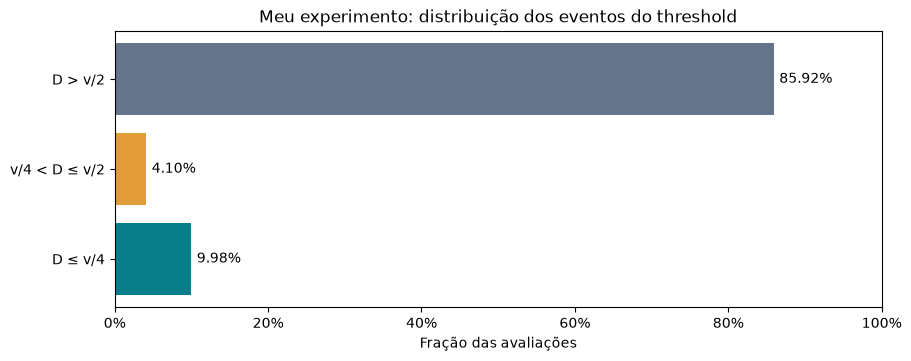

In [3]:
labels = ['D ≤ v/4', 'v/4 < D ≤ v/2', 'D > v/2']
f4, middle, above = diag['pooled_rates']
for label, rate in zip(labels, diag['pooled_rates']):
    print(f'{label}: {rate:.4%}')
print(f'Até v/2: {f4+middle:.4%}')
print(f'Faixa adicional: {100*middle:.2f} pontos percentuais')
print(f'Aumento relativo da incidência: {middle/f4:.2%}')
fig, ax = plt.subplots(figsize=(9,3.5), layout='constrained')
bars = ax.barh(labels, diag['pooled_rates'], color=['#087e8b','#e19c37','#64748b'])
ax.bar_label(bars, labels=[f'{x:.2%}' for x in diag['pooled_rates']], padding=4)
ax.set(xlim=(0,1), xlabel='Fração das avaliações', title='Meu experimento: distribuição dos eventos do threshold')
ax.xaxis.set_major_formatter(PercentFormatter(1))
plt.show()

Os registros afastam a descrição de que o piso v/4 é atingido quase sempre nessa execução. Isso ajuda a interpretar a seletividade do mecanismo. A incidência mensurável também não permite concluir que o limitador seja dispensável: eventos pouco frequentes podem ser relevantes e as contagens não medem sua contribuição para a norma do update ou para a loss.

## 3. A incidência permanece constante durante o treinamento?

Comparamos taxas por intervalo com razões acumuladas. Uma janela usa a soma das contagens dividida pela soma das exposições. O tamanho abaixo pode ser alterado para examinar quanto a descrição depende da suavização.

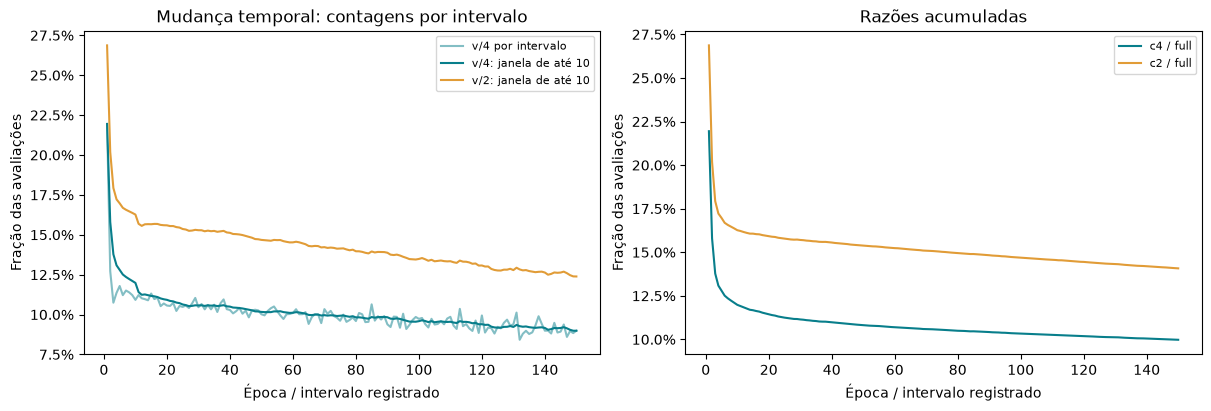

  1– 10: v/4 = 11.984%; v/2 = 16.266%
 11– 40: v/4 = 10.663%; v/2 = 15.333%
 41– 70: v/4 = 10.080%; v/2 = 14.476%
 71–100: v/4 = 9.746%; v/2 = 13.775%
101–130: v/4 = 9.389%; v/2 = 13.068%
141–150: v/4 = 8.986%; v/2 = 12.387%


In [4]:
window = 10  # escolha exploratória: mude para 5 ou 20
rolling = np.stack([pooled_window(diag,max(0,i-window+1),i+1)
                    for i in range(len(full))],axis=1)
fig, ax = plt.subplots(1,2,figsize=(12,4),layout='constrained')
ax[0].plot(epochs,diag['rates'][0],alpha=.5,label='v/4 por intervalo',color='#087e8b')
ax[0].plot(epochs,rolling[0],label=f'v/4: janela de até {window}',color='#087e8b')
ax[0].plot(epochs,rolling[:2].sum(0),label=f'v/2: janela de até {window}',color='#e19c37')
ax[0].set_title('Mudança temporal: contagens por intervalo')
ax[1].plot(epochs,c4/full,label='c4 / full',color='#087e8b')
ax[1].plot(epochs,c2/full,label='c2 / full',color='#e19c37')
ax[1].set_title('Razões acumuladas')
for a in ax:
    a.set(xlabel='Época / intervalo registrado',ylabel='Fração das avaliações')
    a.yaxis.set_major_formatter(PercentFormatter(1))
    a.legend(fontsize=8)
plt.show()

for start,stop in [(0,10),(10,40),(40,70),(70,100),(100,130),(140,150)]:
    rates=pooled_window(diag,start,stop)
    print(f'{start+1:3d}–{stop:3d}: v/4 = {rates[0]:.3%}; v/2 = {rates[:2].sum():.3%}')

As fases mostram mudança na incidência; um percentual final não descreve toda a dinâmica. A comparação entre início e fim é exploratória e não implica queda monótona em todas as épocas. Isso ilustra o uso dos gráficos para questionar a hipótese de comportamento constante, em vez de apenas ilustrar o relatório.

## 4. O que posso inferir sobre outros thresholds?

Temos dois pontos observados. Sem a distribuição completa, o que pode ser obtido para outros thresholds são **limites**, não uma curva interpolada. Esses limites se referem aos eventos da mesma trajetória, não a novos treinamentos com outro piso.

In [5]:
divisors = [1,2,3,4,8,16]
bounds = threshold_bounds(float(f4),float(f4+middle),divisors)
for b in bounds:
    status = 'observado' if b['identified'] else 'apenas limites'
    print(f"v/{b['divisor']:g}: {b['lower']:.3%} a {b['upper']:.3%} — {status}")

v/1: 14.076% a 100.000% — apenas limites
v/2: 14.076% a 14.076% — observado
v/3: 9.978% a 14.076% — apenas limites
v/4: 9.978% a 9.978% — observado
v/8: 0.000% a 9.978% — apenas limites
v/16: 0.000% a 9.978% — apenas limites


## 5. Como isso se conecta à evolução da minha fórmula?

Minha pesquisa combinou análise dos experimentos, identificação de padrões e revisão das hipóteses sobre a regra de atualização. A sequência documentada nos slides é:

1. Explorar uma expressão encontrada pela busca simbólica.
2. Trabalhar com a memória ao quadrado no denominador.
3. Introduzir um piso relativo para limitar a amplificação.
4. Separar a memória m2 da direção m1 e investigar seus coeficientes.
5. Investigar um peso temporal por sigmoide para a correção.

Os contadores diagnosticam o mecanismo de proteção e sua sensibilidade. As curvas de loss, grades de betas e controles de LR investigam outros aspectos da mesma hipótese. Os materiais preservam essa sequência e os resultados, mas não registram qual execução isolada motivou cada mudança. Atribuir uma causa específica a cada alteração exigiria esse histórico.

## 6. Hipóteses e próximos dados

- A saturação não é quase universal nos registros analisados; isso favorece examinar a seletividade do mecanismo.
- A incidência muda com a fase do treino; a análise deve separar acumulados e incrementos.
- A faixa entre v/4 e v/2 mede sensibilidade na trajetória observada, mas não escolhe o melhor piso.
- Para testar se alterar o piso melhora o treino, é preciso comparar execuções com c = 2 / 4 / 8, orçamento equivalente de ajuste de LR e identificação completa das trajetórias.
- Contagens por camada, ganho aplicado e norma do update ajudariam a relacionar incidência e relevância das coordenadas atingidas.

Essas avaliações são correlacionadas: não são trilhões de réplicas para calcular p-valores. As contagens globais também não permitem inferir ativações de neurônios ou vincular diretamente uma época de saturação a uma curva de loss sem o ID de execução.

O [relatório completo](../results/research/report.md) e os CSVs em `results/research/` complementam este caderno com as comparações de loss e os hiperparâmetros dos experimentos do autor.